In [1]:
!pip install pandas numpy duckdb 

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import duckdb
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from pathlib import Path



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


### **Importing Cleaned Datasets From Phase II** 

All of our cleaned datasets are grouped by the following age groups: <br>
- 15 - 24
- 25 - 34
- 35 - 44
- 45 - 54
- 55 - 64
- 65+
Each dataset also includes `num_participants` which shows the number of participants for each age group and `mean_age` which is the average participant age for each age group.

#### **Datasets & Variables:** 

**American Time Use Survey (ATUS) Dataset (`atus`):**
 - `avg_sleeping`: average minutes spent sleeping per day for age group
 - `avg_tv`: the average minutes spent watching TV per day for age group
 - `avg_gaming`: the average minutes spent gaming per day for age group
 - `avg_computer`: the average minutes spent using the computer for leisureper day for age group
 - `avg_artsCrafts`: the average minutes spent doing arts and crafts per day for age group
 - `avg_reading`: the average minutes spent reading for leisure per day for age group
 - `avg_writing`: the average minutes spent writing for leisure per day for age group
 - `avg_exercising`: the average minutes spent exercising per day for age group

**Behavioral Risk Factor Surveillance System Dataset (`mental_health`):**
- `exercised_percentage`: percentage of participants in age group who exercised within the last 30 days
- `no_bad_mental_health_days_percentage`: percentage of participants in age group who had no bad mental health days within the last 30 days
- `half_bad_mental_health_days_percentage`: percentage of participants in age group who had 1-13 bad mental health days within the last 30 days
- `most_bad_mental_health_days_percentage`: percentage of participants in age group who had more than 14 bad mental health days within the last 30 days
  
**Health and Retirement Survey (HRS) Dataset (`hrs`):** <br>
- The HRS data measures the **frequency of participation** in different leisure activities using an ordinal scale: <br>
    - `1`: Respondant participated in activity **daily**
    - `2`: Respondant participated in activity **several times a week**
    - `3`: Respondant participated in activity **once a week**
    - `4`: Respondant participated in activity **several times a month**
    - `5`: Respondant participated in activity **at least once a month**
    - `6`: Respondant **has not participated** in activity **within the past month**
    - `7`: Respondant **never participated** in the activity

- Sleep frequency is measured by an ordinal scale: <br>
    - `1` : Most of the time
    - `2` : Sometimes
    - `3` : Rarely or never
- Recall varibles (`avg_immediate_recall` and `avg_delayed_recall`) are measured on a scale from 1-10, with 1 being only 1 word being recalled correctly, and 10 being all 10 word were recalled correctly. Higher recall scores correspond to better recall. <br>

**Variables:** <br>

- `avg_education_training`: average frequency of paricipants in age group who attended educational training
- `avg_reading`: average frequency of paricipants in age group who read
- `avg_watching_tv`: average frequency of paricipants in age group who watch TV
- `avg_word_games`: average frequency of paricipants in age group who play word games
- `avg_card_games_chess`: average frequency of paricipants in age group who play card games or chess
- `avg_writing`: average frequency of paricipants in age group who write
- `avg_computer_internet`: average frequency of paricipants in age group who use the computer for internet
- `avg_hobbies`: average frequency of paricipants in age group who participate in hobbies
- `avg_exercising`: average frequency of paricipants in age group who exercise
- `avg_walking`: average frequency of paricipants in age group who walk
- `avg_trouble_falling_asleep`: average frequency of paricipants in age group who have trouble falling asleep
- `avg_waking_at_night`: average frequency of paricipants in age group who experience waking at night
- `avg_waking_too_early`: average frequency of paricipants in age group who experience waking too early
- `avg_feeling_rested`: average frequency of paricipants in age group who feel rested
- `avg_immediate_recall`: average immediate-recall scores for participants in age group
- `avg_delayed_recall`: average delayed-recall scores for participants in age group

In [2]:
atus_summ = pd.read_csv("data/atusSummary/atussum_2025.dat")

atus = duckdb.sql("""SELECT "TUCASEID" AS id, 
                            "TEAGE" AS age,
                            "t010101" AS sleeping, 
                            "t120303" AS watchingTV, 
                            "t120307" AS gaming,
                            "t120308" AS computer, 
                            "t120309" AS artsCrafts, 
                            "t120312" AS reading,
                            "t120313" AS writing,
                                ("t130101" + "t130102" + "t130103" + "t130104" + "t130105" +
                                "t130106" + "t130107" + "t130108" + "t130109" + "t130110" + 
                                 + "t130112" + "t130113" + "t130114" +
                                "t130116" + "t130118" + "t130119" + "t130120" +
                                "t130122" + "t130124" + "t130125" + 
                                "t130126" + "t130128" + "t130129" + "t130130" +
                                "t130131" + "t130132" + "t130133" + "t130134" + "t130135" + 
                                "t130136" + "t130199") AS exercising, 
                        FROM atus_summ""").df()
atus.head()

#atus.to_csv("atus.csv", index = False)


,id,age,sleeping,watchingTV,gaming,computer,artsCrafts,reading,writing,exercising
0,20250101250011,55,540,30,0,0,0,0,0,0
1,20250101250092,58,725,270,0,0,0,0,0,0
2,20250101250283,24,390,83,0,0,0,0,0,0
3,20250101250305,25,580,0,0,0,0,135,0,0
4,20250101250594,80,840,290,0,0,0,0,0,0


In [3]:
mental_health = pd.read_csv("data/BRFSS/mental_health.csv")
mental_health.head()

#check data types
print("Original data types of mental_health:")
print(mental_health.dtypes)
print()

#convert _AGE80, _TOTINDA, and _MENT14D to int
mental_health["_AGE80"] = mental_health["_AGE80"].astype(int)
mental_health["_TOTINDA"] = mental_health["_TOTINDA"].astype(int)
mental_health["_MENT14D"] = mental_health["_MENT14D"].astype(int)

print("Current data types of mental_health:")
print(mental_health.dtypes)
print()

mental_health.rename(columns = {"_AGE80": "age", 
                                "_TOTINDA": "exercise", 
                                "_MENT14D": "bad_mental_health_days",
                                "SEQNO": "id"}, inplace = True)

mental_health.head()

#mental_health.to_csv("mental_health.csv", index = False)

Original data types of mental_health:
SEQNO           str
_AGE80      float64
_TOTINDA    float64
_MENT14D    float64
dtype: object

Current data types of mental_health:
SEQNO         str
_AGE80      int64
_TOTINDA    int64
_MENT14D    int64
dtype: object



/tmp/ipykernel_67033/4168640521.py:18: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  mental_health.rename(columns = {"_AGE80": "age",


,id,age,exercise,bad_mental_health_days
0,b'2025000001',71,1,2
1,b'2025000002',80,1,1
2,b'2025000003',68,2,1
3,b'2025000004',80,2,1
4,b'2025000005',64,1,2


In [4]:
hrs = pd.read_csv("cleaned_data/hrs.csv")
hrs2 = duckdb.sql("""SELECT age,
                            trouble_falling_asleep_clean AS trouble_falling_asleep, 
                            waking_at_night_clean AS waking_at_night, 
                            feeling_rested_clean AS feeling_rested, 
                            immediate_recall_clean AS immediate_recall, 
                            delayed_recall_clean AS delayed_recall
                    FROM hrs """).df()
display(hrs2)
hrs2.isna().any(axis=1).sum()
hrs2 = hrs2.dropna()
display(hrs2)
hrs2.to_csv("hrs.csv", index = False)

BinderException: Binder Error: Referenced column "trouble_falling_asleep_clean" not found in FROM clause!
Candidate bindings: "trouble_falling_asleep", "feeling_rested", "age", "delayed_recall", "immediate_recall"

In [ ]:
#importing cleaned ATUS data
atus = pd.read_csv("cleaned_data/atus.csv")
print("American Time Use (ATUS) Data:")
display(atus)
print()

#importing cleaned mental health data 
mental_health = pd.read_csv("cleaned_data/mental_health.csv")
mental_health.head()
print("Mental Health Data:")
display(mental_health)
print()

#importing cleaned HRS data
hrs = pd.read_csv("cleaned_data/hrs.csv")
hrs.head()
print("Health and Retirement Study (HRS) Data:")
display(hrs)
print()

American Time Use (ATUS) Data:


,id,age,sleeping,watchingTV,gaming,computer,artsCrafts,reading,writing,exercising
0,20250101250011,55,540,30,0,0,0,0,0,0
1,20250101250092,58,725,270,0,0,0,0,0,0
2,20250101250283,24,390,83,0,0,0,0,0,0
3,20250101250305,25,580,0,0,0,0,135,0,0
4,20250101250594,80,840,290,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
6141,20251212252316,56,505,0,0,0,0,45,0,60
6142,20251212252317,32,585,120,0,0,0,0,0,0
6143,20251212252319,79,570,180,180,0,0,150,0,0
6144,20251212252322,77,600,240,0,0,0,120,0,60



Mental Health Data:


,id,age,exercise,bad_mental_health_days
0,b'2025000001',71,1,2
1,b'2025000002',80,1,1
2,b'2025000003',68,2,1
3,b'2025000004',80,2,1
4,b'2025000005',64,1,2
...,...,...,...,...
356153,b'2025003840',73,2,1
356154,b'2025003841',66,1,1
356155,b'2025003842',57,1,1
356156,b'2025003843',50,1,3



Health and Retirement Study (HRS) Data:


,age,trouble_falling_asleep,waking_at_night,feeling_rested,immediate_recall,delayed_recall
0,83,2.0,2.0,1.0,4.0,0.0
1,77,3.0,3.0,1.0,7.0,5.0
2,74,3.0,3.0,1.0,5.0,6.0
3,85,2.0,1.0,1.0,4.0,4.0
4,79,1.0,1.0,1.0,6.0,4.0
...,...,...,...,...,...,...
13433,66,1.0,1.0,2.0,6.0,5.0
13434,65,2.0,2.0,3.0,6.0,3.0
13435,67,2.0,2.0,2.0,5.0,2.0
13436,62,3.0,3.0,2.0,7.0,4.0


In [ ]:
datasets = {
    "ATUS": atus,
    "Mental health": mental_health,
    "HRS": hrs,
}

for name, df in datasets.items():
    age = pd.to_numeric(df["age"], errors="coerce").dropna()
    print(f"{name}: {len(age):,} valid ages; range {age.min():.0f}–{age.max():.0f}")

bins = [0, 25, 40, 55, 70, 85, float("inf")]
labels = ["0–24", "25–39", "40–54", "55–69", "70–84", "85+"]

for name, df in datasets.items():
    age = pd.to_numeric(df["age"], errors="coerce").dropna()
    groups = pd.cut(age, bins=bins, labels=labels, right=False)
    print(f"\n{name}")
    print(groups.value_counts(sort=False).to_frame("count")
          .assign(percent=lambda x: 100 * x["count"] / x["count"].sum())
          .round(1))

ATUS: 6,146 valid ages; range 15–85
Mental health: 356,158 valid ages; range 18–80
HRS: 13,438 valid ages; range 27–101

ATUS
       count  percent
age                  
0–24     440      7.2
25–39   1290     21.0
40–54   1307     21.3
55–69   1645     26.8
70–84   1308     21.3
85+      156      2.5

Mental health
        count  percent
age                   
0–24    23238      6.5
25–39   58980     16.6
40–54   71032     19.9
55–69   97877     27.5
70–84  105031     29.5
85+         0      0.0

HRS
       count  percent
age                  
0–24       0      0.0
25–39     35      0.3
40–54   1516     11.3
55–69   6989     52.0
70–84   3935     29.3
85+      963      7.2


In [ ]:
for name, df in datasets.items():
    age = pd.to_numeric(df["age"], errors="coerce")
    shared_ages = df[age.between(40, 84)]
    print(name, len(shared_ages))

ATUS 4260
Mental health 273940
HRS 12440


,ATUS,Mental health,HRS
age,,,
40,103,5213,11
41,91,4135,15
42,88,4864,21
43,88,4657,23
44,89,4450,19
45,98,5064,22
46,76,4207,32
47,86,4448,50
48,80,4598,51


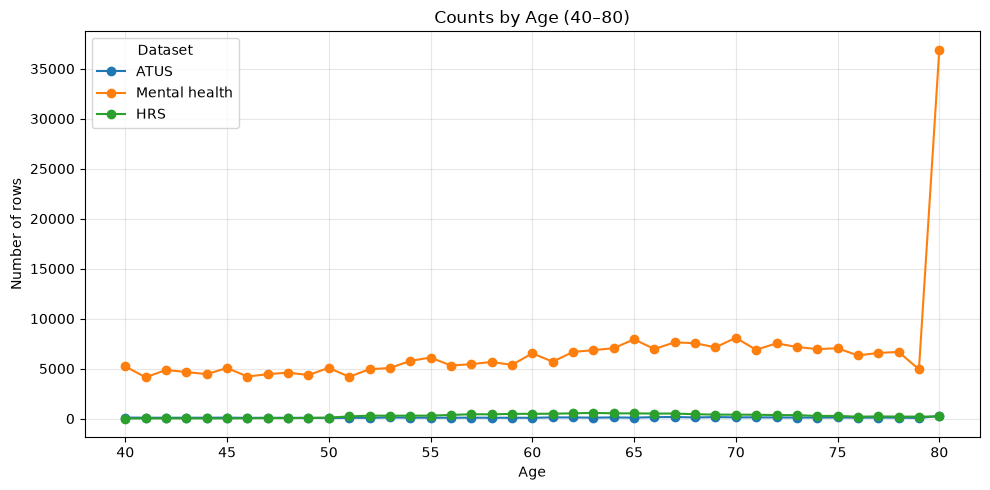

In [ ]:
atus_ages = atus[(atus["age"] >= 40) & (atus["age"] <= 80)]
import matplotlib.pyplot as plt
datasets = {
    "ATUS": atus,
    "Mental health": mental_health,
    "HRS": hrs,
}

age_counts = {}
for name, df in datasets.items():
    ages = df.loc[df["age"].between(40, 80), "age"]
    age_counts[name] = ages.value_counts()

counts_by_age = (
    pd.DataFrame(age_counts)
    .reindex(range(40, 81), fill_value=0)
    .astype(int)
)

display(counts_by_age)

counts_by_age.plot(figsize=(10, 5), marker="o")
plt.title("Counts by Age (40–80)")
plt.xlabel("Age")
plt.ylabel("Number of rows")
plt.xticks(range(40, 81, 5))
plt.grid(True, alpha=0.3)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

# **Data Cleaning & Summarizing for Phase III: 11/09**

In [ ]:
participant_folder = Path("participant_data_cleaned") #using folder Valentina created
summary_folder = Path("data_cleaned")

age_labels = [
    "15-24", "25-34", "35-44",
    "45-54", "55-64", "65+"
]
age_bins = [15, 25, 35, 45, 55, 65, np.inf]

participants = {}

for name in ["atus", "cognitive_data", "mental_health", "hrs"]:
    frame = pd.read_csv(
        participant_folder / f"{name}.csv",
        dtype={"hhid": str, "pn": str}
    )

    age = pd.to_numeric(frame["age"], errors="coerce")
    frame["age"] = age.where(
        age.between(15, 120) & age.mod(1).eq(0)
    )

    frame["age_group"] = pd.cut(
        frame["age"],
        bins=age_bins,
        labels=age_labels,
        right=False
    )

    participants[name] = frame


def summarize(frame, numeric_columns=()):
    grouped = frame.groupby("age_group", observed=False)

    result = grouped.size().rename("num_participants").to_frame()
    result["mean_age"] = grouped["age"].mean()

    for column in numeric_columns:
        result[f"avg_{column}"] = grouped[column].mean()
        result[f"n_{column}"] = grouped[column].count()

    return result


def add_percentages(result, frame, column, labels):
    # Denominator: valid responses to this particular variable.
    valid = frame[column].where(frame[column].isin(labels))

    denominator = (
        frame.assign(valid=valid)
        .groupby("age_group", observed=False)["valid"]
        .count()
    )

    result[f"n_{column}"] = denominator

    for code, label in labels.items():
        numerator = (
            frame.assign(matches=valid.eq(code).astype(int))
            .groupby("age_group", observed=False)["matches"]
            .sum()
        )

        result[f"{label}_percentage"] = (
            numerator.div(denominator.where(denominator.gt(0))) * 100
        )


# ATUS: average minutes.
atus_people = participants["atus"]

atus_variables = [
    "sleeping", "watchingTV", "gaming", "computer",
    "artsCrafts", "reading", "writing", "exercising"
]

atus_summary = summarize(
    atus_people, atus_variables
).rename(columns={
    "avg_watchingTV": "avg_tv",
    "n_watchingTV": "n_tv"
})


# Cognitive assessment: category percentages.
cognitive_people = participants["cognitive_data"]
cognitive_summary = summarize(cognitive_people)

cognitive_categories = {
    "forgetfulness": {
        "Mild": "low_forgetfulness",
        "Moderate": "medium_forgetfulness",
        "High": "high_forgetfulness"
    },
    "distractibility": {
        "Low": "low_distractibility",
        "Medium": "medium_distractibility",
        "High": "high_distractibility"
    },
    "false_triggering": {
        "Yes": "yes_false_triggering",
        "No": "no_false_triggering"
    }
}

for column, labels in cognitive_categories.items():
    add_percentages(
        cognitive_summary, cognitive_people, column, labels
    )


# BRFSS: category percentages.
mental_people = participants["mental_health"]

for column in ["exercise", "bad_mental_health_days"]:
    mental_people[column] = pd.to_numeric(
        mental_people[column], errors="coerce"
    )

mental_summary = summarize(mental_people)

add_percentages(
    mental_summary,
    mental_people,
    "exercise",
    {
        1: "exercised",
        2: "not_exercised"
    }
)

add_percentages(
    mental_summary,
    mental_people,
    "bad_mental_health_days",
    {
        1: "no_bad_mental_health_days",
        2: "half_bad_mental_health_days",
        3: "most_bad_mental_health_days"
    }
)


# HRS: use the cleaned values exported from Phase II.
hrs_people = participants["hrs"]

hrs_activities = [
    "education_training", "reading", "watching_tv",
    "word_games", "card_games_chess", "writing",
    "computer_internet", "hobbies", "exercising", "walking"
]

hrs_sleep = [
    "trouble_falling_asleep", "waking_at_night",
    "waking_too_early", "feeling_rested"
]

# Apply valid-code checks consistently to all leisure variables.
for column in hrs_activities:
    values = pd.to_numeric(hrs_people[column], errors="coerce")
    hrs_people[column] = values.where(values.isin(range(1, 8)))

hrs_summary = summarize(
    hrs_people,
    hrs_activities
    + hrs_sleep
    + [
        "immediate_recall", "delayed_recall",
        "sitting_hours", "sitting_minutes"
    ]
)


# Save only after all four summaries have been created.
summaries = {
    "atus": atus_summary,
    "cognitive_data": cognitive_summary,
    "mental_health": mental_summary,
    "hrs": hrs_summary
}

summary_folder.mkdir(exist_ok=True)

for name, table in summaries.items():
    assert table.index.tolist() == age_labels

    table.reset_index().round(2).to_csv(
        summary_folder / f"{name}.csv",
        index=False
    )

In [ ]:
# Cleaned ATUS summary
atus = atus_summary.reset_index().round(2)
print("American Time Use (ATUS) Data:")
display(atus)
print()

# Cleaned cognitive summary
cognitive_data = cognitive_summary.reset_index().round(2)
print("Cognitive Data:")
display(cognitive_data)
print()

# Cleaned mental health summary
mental_health = mental_summary.reset_index().round(2)
print("Mental Health Data:")
display(mental_health)
print()

# Cleaned HRS summary
hrs = hrs_summary.reset_index().round(2)
print("Health and Retirement Study (HRS) Data:")
display(hrs)
print()

American Time Use (ATUS) Data:


,age_group,num_participants,mean_age,avg_sleeping,n_sleeping,avg_tv,n_tv,avg_gaming,n_gaming,avg_computer,n_computer,avg_artsCrafts,n_artsCrafts,avg_reading,n_reading,avg_writing,n_writing,avg_exercising,n_exercising
0,15-24,440,19.94,610.01,440,115.74,440,54.35,440,19.20,440,3.72,440,10.71,440,0.30,440,0.14,440
1,25-34,777,29.94,548.45,777,122.82,777,33.75,777,14.19,777,1.49,777,11.95,777,0.22,777,0.14,777
2,35-44,972,39.36,535.86,972,117.10,972,18.23,972,7.39,972,1.42,972,13.39,972,0.14,972,0.10,972
3,45-54,848,49.61,532.98,848,152.54,848,10.98,848,12.02,848,1.64,848,13.88,848,0.15,848,0.07,848
4,55-64,979,59.77,530.26,979,194.79,979,10.48,979,8.40,979,2.22,979,16.80,979,0.54,979,0.17,979
5,65+,2130,73.44,536.60,2130,261.70,2130,16.94,2130,11.64,2130,4.16,2130,34.61,2130,0.50,2130,0.12,2130



Cognitive Data:


,age_group,num_participants,mean_age,n_forgetfulness,low_forgetfulness_percentage,medium_forgetfulness_percentage,high_forgetfulness_percentage,n_distractibility,low_distractibility_percentage,medium_distractibility_percentage,high_distractibility_percentage,n_false_triggering,yes_false_triggering_percentage,no_false_triggering_percentage
0,15-24,388,20.99,388,88.92,7.73,3.35,388,32.99,31.44,35.57,388,52.58,47.42
1,25-34,541,29.42,541,91.50,6.28,2.22,541,33.27,34.57,32.16,541,48.24,51.76
2,35-44,419,39.12,419,89.50,7.16,3.34,419,37.71,31.50,30.79,419,50.60,49.40
3,45-54,41,45.80,41,87.80,9.76,2.44,41,29.27,36.59,34.15,41,48.78,51.22
4,55-64,9,58.11,9,77.78,22.22,0.00,9,55.56,0.00,44.44,9,55.56,44.44
5,65+,1,65.00,1,100.00,0.00,0.00,1,0.00,100.00,0.00,1,100.00,0.00



Mental Health Data:


,age_group,num_participants,mean_age,n_exercise,exercised_percentage,not_exercised_percentage,n_bad_mental_health_days,no_bad_mental_health_days_percentage,half_bad_mental_health_days_percentage,most_bad_mental_health_days_percentage
0,15-24,23238,21.03,23188,85.38,14.62,22857,39.45,40.43,20.12
1,25-34,37370,29.59,37320,82.91,17.09,36819,41.14,38.77,20.09
2,35-44,44929,39.56,44858,81.95,18.05,44234,46.95,33.87,19.18
3,45-54,47713,49.65,47600,78.40,21.60,46934,53.35,29.07,17.57
4,55-64,60683,59.72,60514,75.34,24.66,59688,60.72,24.24,15.04
5,65+,142225,73.83,141704,72.32,27.68,139142,73.20,17.81,8.99



Health and Retirement Study (HRS) Data:


,age_group,num_participants,mean_age,avg_education_training,n_education_training,avg_reading,n_reading,avg_watching_tv,n_watching_tv,avg_word_games,...,avg_feeling_rested,n_feeling_rested,avg_immediate_recall,n_immediate_recall,avg_delayed_recall,n_delayed_recall,avg_sitting_hours,n_sitting_hours,avg_sitting_minutes,n_sitting_minutes
0,15-24,0,NaN,NaN,0,NaN,0,NaN,0,NaN,...,NaN,0,NaN,0,NaN,0,NaN,0,NaN,0
1,25-34,11,31.36,4.50,2,1.50,2,2.50,2,5.00,...,2.73,11,6.36,11,6.00,11,5.18,11,0.00,11
2,35-44,120,41.08,6.20,20,3.00,20,1.65,20,4.16,...,1.92,120,6.02,116,5.04,115,5.30,112,2.59,87
3,45-54,1494,51.63,6.06,289,3.39,289,1.70,287,4.62,...,1.89,1492,5.95,1436,4.85,1433,5.97,1462,1.47,1131
4,55-64,5187,59.94,6.28,1310,3.13,1313,1.46,1312,4.33,...,1.76,5173,5.74,4666,4.68,4652,5.83,4983,2.45,3298
5,65+,8975,75.26,6.49,2767,2.55,2769,1.35,2775,4.15,...,1.59,8913,5.05,7419,3.98,7364,5.52,8428,2.43,5053


In [ ]:
# Save participant-level cleaned datasets
for name, frame in participants.items():
    frame.to_csv(
        summary_folder / f"{name}_people.csv",
        index=False
    )

In [ ]:
h1_regression_data = pd.read_csv("data_cleaned/hrs_people.csv")
# Leisure questions were administered to eligible respondents.
eligible = pd.to_numeric(
    h1_regression_data["lb_eligible"], errors="coerce"
).eq(1)

h1_regression_data = h1_regression_data.loc[eligible].copy()

activities = ["exercising", "reading", "hobbies", "watching_tv"]

# Reverse activity codes:
# 0 = never, 6 = daily.
# Higher scores now mean more frequent participation.
for activity in activities:
    values = pd.to_numeric(
        h1_regression_data[activity], errors="coerce"
    )

    h1_regression_data[f"{activity}_participation"] = (
        7 - values.where(values.isin(range(1, 8)))
    )
h1_regression_data.head()

h1_regression_data = h1_regression_data[
    [
        "age",
        "immediate_recall",
        "delayed_recall",
        "exercising_participation",
        "reading_participation",
        "hobbies_participation",
        "watching_tv_participation"
    ]
].copy()

"""h1_regression_data.head()
h1_regression_data.to_csv(
    "data_cleaned/h1_regression_data.csv",
    index=False
) """
predictors = [
    "age",
    "exercising_participation",
    "reading_participation",
    "hobbies_participation",
    "watching_tv_participation

In [ ]:
immediate_model_data = (
    h1_regression_data[
        predictors + ["immediate_recall"]
    ]
    .dropna()
)

delayed_model_data = (
    h1_regression_data[
        predictors + ["delayed_recall"]
    ]
    .dropna()
)
#immediate_model_data.to_csv("h1_hrs_immediate_model_data.csv", index = False)
#delayed_model_data.to_csv("h1_hrs_delayed_model_data.csv", index = False)

display(immediate_model_data)
print(max(immediate_model_data["exercising_participation"]))
print(min(immediate_model_data["exercising_participation"]))
print(max(immediate_model_data["age"]))


,age,exercising_participation,reading_participation,hobbies_participation,watching_tv_participation,immediate_recall
1,66,6.0,6.0,6.0,6.0,5.0
4,85,6.0,6.0,6.0,6.0,4.0
17,83,5.0,6.0,1.0,6.0,4.0
18,81,5.0,5.0,0.0,6.0,4.0
19,83,0.0,6.0,0.0,6.0,4.0
...,...,...,...,...,...,...
15769,65,1.0,1.0,0.0,5.0,5.0
15770,48,3.0,2.0,0.0,6.0,4.0
15774,72,4.0,4.0,0.0,6.0,3.0
15775,82,6.0,1.0,0.0,6.0,2.0


6.0
0.0
101


Regression Analysis Leisure Participation and Recall

We use the cleaned HRS participant records to examine whether leisure participation is associated with memory recall, holding age and the other included activities constant. We fit two multiple linear regressions: one for **immediate recall** and one for **delayed recall**. Both outcomes measure the number of words correctly recalled, from 0 to 10.

**Preparing the data.** We select respondents eligible for the Leave-Behind Questionnaire and include age, exercise, reading, hobbies, and television viewing as predictors. We reverse the activity codes so that higher values indicate more frequent participation: **0 = never** and **6 = daily**. Each model uses respondents with valid values for all its required variables.

**Fitting the models.** Following the train/test approach discussed in class, we randomly divide each model’s available records into **70% training data and 30% test data**. We use the training data to fit an ordinary least-squares regression, which chooses coefficients that minimize the sum of squared residuals. We explicitly add an intercept using `sm.add_constant()`.

**Evaluating predictions.** We use the fitted model to predict recall scores for both sets. We calculate **mean absolute error (MAE)** and **root mean squared error (RMSE)**, measured in words recalled. Lower values indicate smaller prediction errors. We also compare test performance with a baseline that predicts the training sample’s mean recall score for everyone. Much larger errors on the test set than on the training set may indicate overfitting.

**Checking model fit.** We plot training residuals—observed scores minus predicted scores—against predicted scores. We look for residuals scattered around zero without clear curvature or a changing spread. We also inspect their distribution and the correlations among predictors to identify possible problems with model assumptions or overlapping information.

**Interpreting coefficients.** Each activity coefficient describes the expected difference in recall score associated with a one-step increase in participation frequency, **all else equal**. Positive coefficients for exercise, reading, or hobbies would be in the direction predicted by Hypothesis 1. A negative television coefficient would indicate that more frequent television viewing is associated with lower recall.

**Assessing statistical evidence.** The regression tables report coefficient estimates, standard errors, two-sided p-values, and 95% confidence intervals. We apply a **Bonferroni correction** across the eight activity-coefficient tests: four activities in each of two models. This uses a significance threshold of **0.05 / 8 = 0.00625** to limit false positives across those tests. The reported 95% confidence intervals are individual intervals and are not adjusted by this correction.

In [7]:
atus_people = pd.read_csv("data_cleaned/atus_people.csv")

atus_sleep_data = atus_people[
    [
        "age",
        "sleeping",
        "watchingTV",
        "gaming",
        "reading",
        "artsCrafts",
        "exercising"
    ]
].copy()

atus_sleep_data = (
    atus_sleep_data
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

atus_sleep_data.to_csv(
    "data_cleaned/atus_sleep_data.csv",
    index=False
)